                new_deaths_smoothed_per_million  \
country                                           
Brazil                                     0.00   
Germany                                    0.47   
India                                      0.00   
Japan                                      0.00   
South Africa                               0.00   
Sweden                                     0.00   
United Kingdom                             0.00   
United States                              0.00   

                people_fully_vaccinated_per_hundred  stringency_index  
country                                                                
Brazil                                         0.71              0.55  
Germany                                        0.66              0.55  
India                                          0.49              0.55  
Japan                                          0.67              0.55  
South Africa                                   0.80      

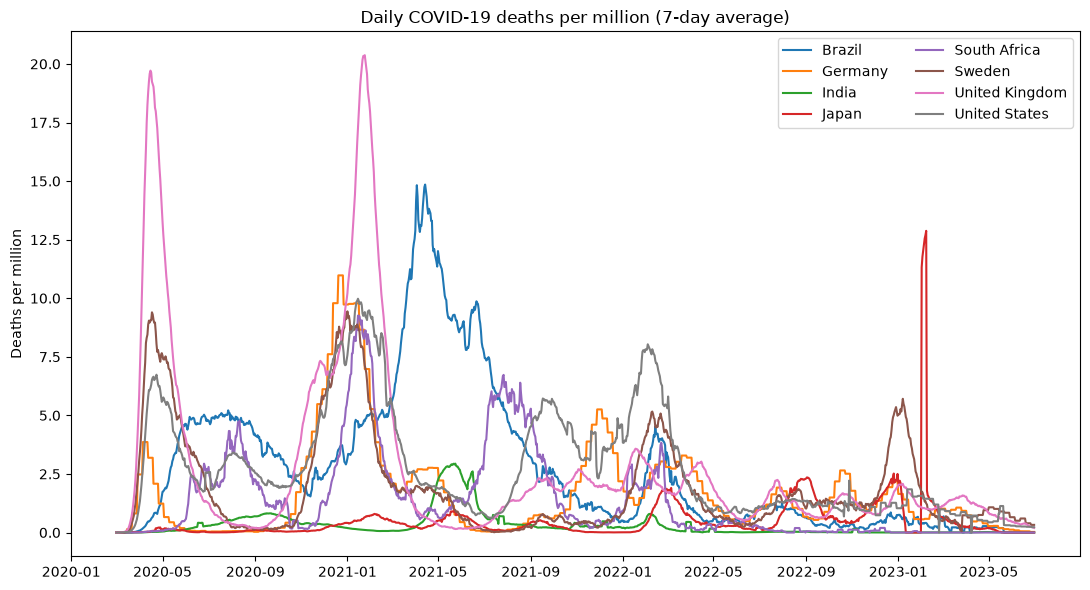

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

sub = pd.read_csv("../data/covid_focus.csv", parse_dates=["date"])

# 1. How much is missing, per country?
check_cols = ["new_deaths_smoothed_per_million",
              "people_fully_vaccinated_per_hundred",
              "stringency_index"]
print(sub.groupby("country")[check_cols].apply(lambda g: g.isna().mean().round(2)))

# 2. Last date each country has a death value above zero
print(sub[sub["new_deaths_smoothed_per_million"] > 0]
      .groupby("country")["date"].max())

# 3. Analysis window shared by all countries
win = sub[(sub["date"] >= "2020-03-01") & (sub["date"] <= "2023-06-30")].copy()

# 4. Wave comparison chart
fig, ax = plt.subplots(figsize=(11, 6))
for name, g in win.groupby("country"):
    ax.plot(g["date"], g["new_deaths_smoothed_per_million"], label=name, linewidth=1.5)
ax.set_title("Daily COVID-19 deaths per million (7-day average)")
ax.set_ylabel("Deaths per million")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()